# ESM-2 embeddings of the DENV envelope protein (South Asia)
Kaggle, Internet ON, GPU T4. Input: lineage_assigned.csv. Output: /kaggle/working/out.

In [1]:
!pip install -q biopython transformers
import os, io, re, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import Entrez, SeqIO, Align
from Bio.Seq import Seq
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Entrez.email = "mdabusayemedu@gmail.com"
os.makedirs("out", exist_ok=True)

P = "/kaggle/working/lineage_assigned.csv"
if not os.path.exists(P):
    c = glob.glob("/kaggle/input/**/lineage_assigned.csv", recursive=True)
    assert c, "Add lineage_assigned.csv as a Kaggle dataset"
    P = c[0]
m = pd.read_csv(P)
m = m[m.lineage.notna() & (m.lineage != "unassigned")].copy()
m["major"] = m.lineage.str.split(".").str[0]
print(len(m), "assigned sequences")


2459 assigned sequences


In [2]:
# Reference genomes and the coordinates of the envelope (E) gene
REFS = {1: "NC_001477", 2: "NC_001474", 3: "NC_001475", 4: "NC_002640"}
ref_E = {}
for s, acc in REFS.items():
    h = Entrez.efetch(db="nuccore", id=acc, rettype="gb", retmode="text")
    rec = next(SeqIO.parse(io.StringIO(h.read()), "genbank")); h.close()
    feats = [f for f in rec.features if f.type == "mat_peptide" and "envelope" in f.qualifiers.get("product", [""])[0].lower()]
    f = feats[0]
    st, en = int(f.location.start), int(f.location.end)
    ref_E[s] = rec.seq[st:en]
    print("DENV-%d" % s, acc, "E gene", st + 1, en, "length", en - st, "nt =", (en - st) // 3, "aa")


DENV-1 NC_001477 E gene 935 2419 length 1485 nt = 495 aa
DENV-2 NC_001474 E gene 937 2421 length 1485 nt = 495 aa
DENV-3 NC_001475 E gene 935 2413 length 1479 nt = 493 aa
DENV-4 NC_002640 E gene 939 2423 length 1485 nt = 495 aa


In [3]:
# Download the nucleotide sequences of all assigned records
seqs = {}
accs = list(dict.fromkeys(m.acc))
for i in range(0, len(accs), 200):
    for attempt in range(3):
        try:
            h = Entrez.efetch(db="nuccore", id=",".join(accs[i:i+200]), rettype="fasta", retmode="text")
            for r in SeqIO.parse(io.StringIO(h.read()), "fasta"):
                seqs[r.id] = r.seq
            h.close(); break
        except Exception as e:
            print("retry", e); time.sleep(3)
    time.sleep(0.4)
print(len(seqs), "sequences downloaded")


2453 sequences downloaded


In [4]:
# Cut the E gene out of each sequence and translate it
al = Align.PairwiseAligner(); al.mode = "local"
al.match_score = 2; al.mismatch_score = -1; al.open_gap_score = -4; al.extend_gap_score = -2

def e_protein(seq, ref):
    a = al.align(seq, ref)[0]
    q0, q1 = int(a.aligned[0][0][0]), int(a.aligned[0][-1][1])
    r0 = int(a.aligned[1][0][0])
    f = (3 - r0 % 3) % 3
    nt = seq[q0 + f:q1]
    nt = nt[: len(nt) // 3 * 3]
    return str(nt.translate())

rows = []
for r in m.itertuples():
    if r.acc not in seqs:
        continue
    p = e_protein(seqs[r.acc], ref_E[r.serotype])
    rows.append((r.acc, p))
prot = pd.DataFrame(rows, columns=["acc", "prot"])
prot["n_aa"] = prot.prot.str.len()
prot["stops"] = prot.prot.str.count(r"\*")
d = m.drop_duplicates("acc").merge(prot, on="acc")
d = d[(d.n_aa >= 400) & (d.stops <= 1)].copy()
d["prot"] = d.prot.str.replace("*", "", regex=False)
print("kept", len(d), "of", len(m), "| median length", int(d.n_aa.median()))


kept 2452 of 2459 | median length 495


In [5]:
# Mean-pooled ESM-2 embeddings of the E protein
import torch
from transformers import AutoTokenizer, EsmModel
dev = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained("facebook/esm2_t12_35M_UR50D")
mdl = EsmModel.from_pretrained("facebook/esm2_t12_35M_UR50D").to(dev).eval()
vecs = []
plist = d.prot.tolist()
with torch.no_grad():
    for i in range(0, len(plist), 32):
        b = tok(plist[i:i+32], return_tensors="pt", padding=True, truncation=True, max_length=600).to(dev)
        o = mdl(**b).last_hidden_state
        mask = b["attention_mask"].unsqueeze(-1)
        vecs.append(((o * mask).sum(1) / mask.sum(1)).cpu().numpy())
X = np.vstack(vecs)
print(X.shape)
np.save("out/esm2_embeddings.npy", X); d.drop(columns=["prot"]).to_csv("out/embedding_index.csv", index=False)


config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  136MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


(2452, 480)


In [6]:
# Task A: can the embedding recover the lineage? Stratified 5-fold CV, compared with a dummy baseline
from sklearn.dummy import DummyClassifier
res = []
for s in sorted(d.serotype.unique()):
    for level in ["major", "lineage"]:
        idx = d.index[d.serotype == s]
        sub = d.loc[idx]
        keep = sub[level].map(sub[level].value_counts()) >= 10
        ii = np.where((d.serotype == s).values)[0][keep.values]
        y = d[level].values[ii]
        if len(set(y)) < 2: continue
        Z = StandardScaler().fit_transform(X[ii])
        cv = StratifiedKFold(5, shuffle=True, random_state=0)
        pr = cross_val_predict(LogisticRegression(max_iter=2000), Z, y, cv=cv)
        pb = cross_val_predict(DummyClassifier(strategy="most_frequent"), Z, y, cv=cv)
        res.append({"serotype": "DENV-%d" % s, "level": level, "classes": len(set(y)), "n": len(y),
                    "macroF1_embedding": round(f1_score(y, pr, average="macro"), 3),
                    "macroF1_baseline": round(f1_score(y, pb, average="macro"), 3)})
ra = pd.DataFrame(res); ra.to_csv("out/taskA_lineage_recovery.csv", index=False); print(ra.to_string(index=False))


serotype   level  classes   n  macroF1_embedding  macroF1_baseline
  DENV-1   major        8 523              0.793             0.103
  DENV-1 lineage       11 512              0.735             0.055
  DENV-2   major        3 932              0.938             0.269
  DENV-2 lineage        8 907              0.938             0.086
  DENV-3   major        4 688              0.975             0.175
  DENV-3 lineage        7 683              0.854             0.084
  DENV-4   major        3 287              0.943             0.279
  DENV-4 lineage        5 286              0.814             0.163


In [7]:
# Task B: leave-one-country-out. Train on all other countries, test on the held-out country (major lineage)
res = []
for s in sorted(d.serotype.unique()):
    for c in d[d.serotype == s].country.unique():
        te = ((d.serotype == s) & (d.country == c)).values
        tr = ((d.serotype == s) & (d.country != c)).values
        if te.sum() < 30 or tr.sum() < 30: continue
        ytr, yte = d.major.values[tr], d.major.values[te]
        ok = np.isin(yte, np.unique(ytr))
        if ok.sum() < 20 or len(set(ytr)) < 2: continue
        sc = StandardScaler().fit(X[tr])
        clf = LogisticRegression(max_iter=2000).fit(sc.transform(X[tr]), ytr)
        pr = clf.predict(sc.transform(X[te][ok]))
        res.append({"serotype": "DENV-%d" % s, "held_out": c, "n_test": int(ok.sum()),
                    "unseen_lineage_share_pct": round(100 * (1 - ok.mean()), 1), "accuracy": round(accuracy_score(yte[ok], pr), 3)})
rb = pd.DataFrame(res); rb.to_csv("out/taskB_leave_one_country_out.csv", index=False); print(rb.to_string(index=False))


serotype   held_out  n_test  unseen_lineage_share_pct  accuracy
  DENV-1      India     327                      16.6     0.881
  DENV-1  Sri Lanka      38                       0.0     0.974
  DENV-2 Bangladesh     107                       0.0     0.981
  DENV-2      India     428                       2.7     0.841
  DENV-2  Sri Lanka     266                       0.0     0.959
  DENV-2      Nepal      67                       0.0     0.910
  DENV-2   Maldives      29                       3.3     1.000
  DENV-3 Bangladesh     192                       0.0     1.000
  DENV-3      India     289                      17.2     0.931
  DENV-3  Sri Lanka      73                       0.0     1.000
  DENV-3     Bhutan      44                       0.0     1.000


In [8]:
# Task C: does embedding distance between countries track lineage-frequency distance (Bray-Curtis)?
res = []
for s in sorted(d.serotype.unique()):
    sub = d[d.serotype == s]
    cs = [c for c, n in sub.country.value_counts().items() if n >= 30]
    if len(cs) < 4: continue
    cent = np.vstack([X[np.where((d.serotype == s).values & (d.country == c).values)[0]].mean(0) for c in cs])
    ed = pdist(cent, "cosine")
    fr = pd.crosstab(sub.country, sub.lineage).loc[cs]
    fr = fr.div(fr.sum(1), axis=0)
    bd = pdist(fr.values, "braycurtis")
    rho, p = spearmanr(ed, bd)
    res.append({"serotype": "DENV-%d" % s, "countries": len(cs), "pairs": len(ed), "spearman_rho": round(rho, 3), "p": round(p, 4)})
rc = pd.DataFrame(res); rc.to_csv("out/taskC_distance_agreement.csv", index=False); print(rc.to_string(index=False))


serotype  countries  pairs  spearman_rho      p
  DENV-2          5     10        -0.152 0.6761
  DENV-3          4      6         0.551 0.2574


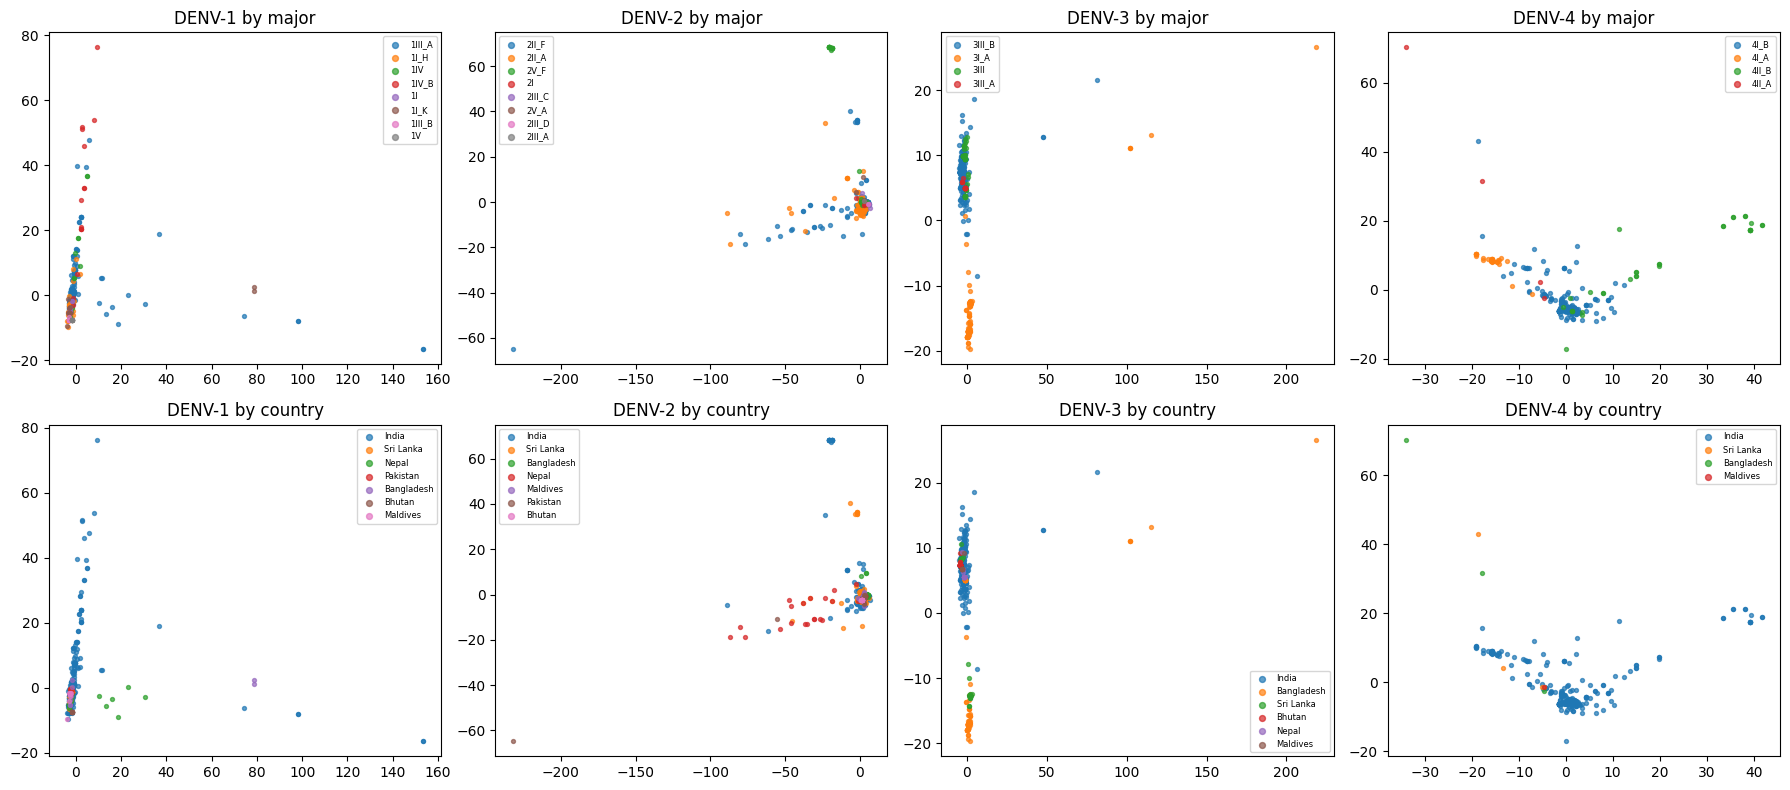

In [9]:
# Figure: PCA of the embeddings per serotype, coloured by major lineage and by country
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, s in enumerate(sorted(d.serotype.unique())):
    ii = np.where((d.serotype == s).values)[0]
    if len(ii) < 20: continue
    Z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(X[ii]))
    for row, col in enumerate(["major", "country"]):
        ax = axes[row, j]
        top = d[col].values[ii]
        keep = pd.Series(top).value_counts().index[:8]
        for k in keep:
            w = top == k
            ax.scatter(Z[w, 0], Z[w, 1], s=8, label=k, alpha=0.7)
        ax.set_title("DENV-%d by %s" % (s, col)); ax.legend(fontsize=6, markerscale=1.5)
plt.tight_layout(); plt.savefig("out/fig4_embedding_pca.png", dpi=200); plt.show()


In [10]:
from sklearn.feature_extraction.text import CountVectorizer
cv3 = CountVectorizer(analyzer="char", ngram_range=(3, 3), lowercase=False)
res = []
for s in sorted(d.serotype.unique()):
    for level in ["major", "lineage"]:
        sub = d[d.serotype == s]
        keep = sub[level].map(sub[level].value_counts()) >= 10
        ii = np.where((d.serotype == s).values)[0][keep.values]
        y = d[level].values[ii]
        if len(set(y)) < 2: continue
        K = cv3.fit_transform(d.prot.values[ii]).astype(float)
        K = StandardScaler(with_mean=False).fit_transform(K)
        skf = StratifiedKFold(5, shuffle=True, random_state=0)
        pk = cross_val_predict(LogisticRegression(max_iter=500), K, y, cv=skf)
        res.append({"serotype": "DENV-%d" % s, "level": level, "macroF1_3mer": round(f1_score(y, pk, average="macro"), 3)})
rk = pd.DataFrame(res)
cmp = ra.merge(rk, on=["serotype", "level"])
cmp.to_csv("out/taskA_with_3mer_baseline.csv", index=False)
print(cmp.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

serotype   level  classes   n  macroF1_embedding  macroF1_baseline  macroF1_3mer
  DENV-1   major        8 523              0.793             0.103         0.838
  DENV-1 lineage       11 512              0.735             0.055         0.787
  DENV-2   major        3 932              0.938             0.269         0.960
  DENV-2 lineage        8 907              0.938             0.086         0.969
  DENV-3   major        4 688              0.975             0.175         0.989
  DENV-3 lineage        7 683              0.854             0.084         0.888
  DENV-4   major        3 287              0.943             0.279         0.973
  DENV-4 lineage        5 286              0.814             0.163         0.876
